Procedimiento del Análisis Discriminante

1. Establecer un modelo para $p(x|y=c)$ para cada clase $c$.
2. Estimar los parámetros $\theta_c$ de cada modelo mediante máxima verosimilitud.
3. Calcular la probabilidad a posteriori $p(y=c|x)$ usando el Teorema de Bayes.
4. Asignar las instancias que deseamos predecir a la clase que maximice la probabilidad posterior.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
# Cargar el dataset MNIST
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')
y = y.astype(int)  # Convertir las etiquetas a enteros


## Binarizamos los datos

In [24]:
# Binarizar los datos: píxeles mayores que 127.5 se convierten en 1, de lo contrario en 0
X_binarized = np.where(X>127.5, 1, 0)

# Dividir el dataset en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_binarized, y, test_size=0.2, random_state=42)

# 1 - Escogemos un modelo para $p(x|y=c)$ para cada clase $c$: Naive Bayes binarizado.

Ahora vamos a implementar el algoritmo Naive Bayes. Naive Bayes se basa en el teorema de Bayes, con la "ingenua" suposición de independencia entre las características. La fórmula para el teorema de Bayes es:

# 2 - Estimar los parámetros $\theta_c$ de cada modelo mediante máxima verosimilitud.

\begin{align*}
        \hat{\theta}_{ic} &= \frac{\sum_{n=1}^N x_{ni} \ \mathbb{I}(y_n = c)}{\sum_{n=1}^N \mathbb{I}(y_n = c)}  = \frac{N_{ic}}{N_c} \\\\
        \hat{\pi_c} &= \frac{\sum_{n=1}^N \mathbb{I}(y_n = c)}{N} = \frac{N_c}{N}
\end{align*}

Función para extraer las imágenes de una clase

In [25]:
X_train.shape

(56000, 784)

In [26]:
def extract_class_images(X, y, class_label):
    """
    Extrae todas las imágenes que pertenecen a una clase específica.

    Parámetros:
        X (numpy.ndarray): Las imágenes del conjunto de datos (ej., MNIST).
        y (numpy.array): Las etiquetas correspondientes de las imágenes.
        class_label (int): La etiqueta de la clase para extraer las imágenes.

    Devuelve:
        numpy.ndarray: Un array de las imágenes que pertenecen a la clase específica.
    """
    # Obtener las posiciones correspondientes a la clase en cuestión
    mask = y == class_label

    # Extraer las imágenes correspondientes
    extracted_images = X[mask]

    # Asegurarse de que las imágenes extraídas corresponden a la clase correcta
    assert (y[y == class_label] == class_label).all(), "No todas las imágenes extraídas corresponden a la clase solicitada."
    return extracted_images


# Crear un conjunto de datos de prueba pequeño y sencillo
X_check = np.array([[0, 1], [1, 1], [0, 0]])  # Supongamos que son 'imágenes' con dos píxeles
y_check = np.array([0, 1, 0])  # Etiquetas correspondientes
class_label_check = 0  # Clase que queremos extraer

extract_class_images(X=X_check, y=y_check, class_label = class_label_check)

array([[0, 1],
       [0, 0]])

Debe dar

```
array([[0, 1],
       [0, 0]])
```



### 2.1 - Función para estimar las probabilidades a priori de cada clase:

\begin{align*}
    \hat{\pi_c} &= \frac{\sum_{n=1}^N \mathbb{I}(y_n = c)}{N} = \frac{N_c}{N}
\end{align*}

In [27]:
# Ejemplo de etiquetas de clase, donde cada número representa una categoría diferente
y_check = np.array([0, 1, 2, 1, 1, 0, 2, 0, 0, 1, 2, 0, 1, 2, 1])

# Obtener clases únicas y su recuento correspondiente
clases, cantidades = np.unique(y_check, return_counts=True)

# Mostrar resultados
print("Clases:", clases)  # Clases únicas
print("Cantidad por clase:", cantidades)  # Cantidad de elementos por clase


Clases: [0 1 2]
Cantidad por clase: [5 6 4]


In [28]:
import numpy as np

def calculate_class_priors(y):
    """
    Calcula las probabilidades a priori de las clases basadas en las etiquetas.

    Parámetros:
        y (numpy.array): Las etiquetas del conjunto de datos.

    Retorna:
        numpy.ndarray: Un array que contiene la probabilidad a priori para cada clase.
    """
    # Contar la aparición de cada clase en el conjunto de etiquetas 'y'
    classes, counts = np.unique(y, return_counts=True)


    # Calcular las probabilidades a priori para cada clase.
    # La probabilidad a priori de una clase es el número de apariciones de esa clase dividido por
    # el número total de muestras.
    priors = counts / len(y)

    # Asegurarse de que las probabilidades a priori suman 1 (esto es una buena práctica para
    # verificar la validez de las probabilidades).
    assert np.isclose(priors.sum(), 1.0), "Las probabilidades a priori no suman 1."  # assert condiciion, mesaje de error si la condición no se cumple. 

    # Retornar el array de las probabilidades a priori calculadas.
    return priors

# Crear un conjunto de datos de prueba pequeño y sencillo para etiquetas
y_check = np.array([0, 1, 0, 1, 0])  # Ejemplo de etiquetas

# Llamar a la función y almacenar las probabilidades a priori resultantes
priors_check = calculate_class_priors(y=y_check)

# Imprimir las probabilidades a priori calculadas para verificar
print("Probabilidades a priori calculadas:", priors_check)

# Verificación simple de las probabilidades a priori calculadas (sin usar una función de test independiente)
# Debería haber dos clases con probabilidades 0.6 y 0.4 respectivamente para este conjunto de datos de prueba
assert np.isclose(priors_check[0], 0.6), "Probabilidad a priori incorrecta para la clase 0."
assert np.isclose(priors_check[1], 0.4), "Probabilidad a priori incorrecta para la clase 1."
print("La verificación de las probabilidades a priori pasó correctamente.")


Probabilidades a priori calculadas: [0.6 0.4]
La verificación de las probabilidades a priori pasó correctamente.


### 2.2 - Función para estimar los parámetros

Utilizaremos el suavizado de Laplace:

\begin{align*}
        \hat{\theta}_{ic}^{\text{(Laplace)}}  = \frac{N_{ic}+1}{N_c+2}
\end{align*}

In [29]:
X.shape

(70000, 784)

In [30]:
Z = X.sum(axis = 1)
Z.shape

(70000,)

In [31]:
Z = X.sum(axis = 0)
Z.shape

(784,)

In [32]:
X.shape[0]

70000

In [33]:
def get_theta_estimate(X_c):
    """
    Calcula las estimaciones de parámetros theta para una clase dada, aplicando suavizado de Laplace.

    Parámetros:
        X_c (numpy.ndarray): Las imágenes del conjunto de datos que pertenecen a una clase específica.

    Retorna:
        numpy.ndarray: Un array que contiene la probabilidad de que cada píxel sea blanco (1) en imágenes
                       de la clase específica, con suavizado de Laplace aplicado.
    """
    # X_c es una matriz donde cada fila contiene los píxeles de una image (784)
    # y tendrá tantas filas como imagen de la clase en cuestión.

    #Calculamos N_ic con matrices (intentarlo mejor sin bucles)
    N_ic = X_c.sum(axis=0)

    #Calculamos N_c
    N_c = X_c.shape[0]

    theta_ic_estimates = (N_ic + 1) / (N_c + 2)

    # Asegurarse de que todas las probabilidades estén entre 0 y 1
    assert np.all((theta_ic_estimates >= 0) & (theta_ic_estimates <= 1)), "Las probabilidades estimadas deben estar entre 0 y 1."

    # Retornar el array de las estimaciones de theta para la clase.
    return theta_ic_estimates

# Crear un conjunto de datos de prueba pequeño y sencillo
X_check_class = np.array([[0, 1], [1, 1], [1, 0]])  # Supongamos que estas son todas las imágenes de una clase específica

# Llamar a la función y almacenar las estimaciones de theta resultantes
theta_estimates_check = get_theta_estimate(X_check_class)

# Imprimir las estimaciones de theta para verificar
print("Estimaciones de Theta calculadas:", theta_estimates_check)

# Verificación simple de las estimaciones de theta (sin usar una función de prueba independiente)
# Asegurar que todas las estimaciones estén entre 0 y 1
assert np.all((theta_estimates_check >= 0) & (theta_estimates_check <= 1)), "Las estimaciones de Theta deben estar entre 0 y 1."
print("La verificación de las estimaciones de Theta pasó correctamente.")


Estimaciones de Theta calculadas: [0.6 0.6]
La verificación de las estimaciones de Theta pasó correctamente.


In [34]:
# X_c es una matriz donde cada fila contiene los píxeles de una image (784)
# y tendrá tantas filas como imagen de la clase en cuestión.
X_c_check = extract_class_images(X=X_binarized, y=y, class_label=1)

X_c_check.shape

(7877, 784)

In [40]:
# Si sumamos todos los elementos de cada columna, tendremos los N_ic de la clase c
X_c_check.sum(axis=0).shape

(784,)

In [ ]:
def fit_naive_bayes(X, y):
    """
    Calcula las probabilidades a priori y las estimaciones de los parámetros para cada clase y píxel.

    Parámetros:
        X (numpy.ndarray): Conjunto de imágenes
        y (numpy.ndarray): Etiquetas (clases)

    Retorna:
        tuple: (priors_estimates, thetas_estimates)
    """
    # Obtener el número de muestras (imágenes) y de características (píxeles) del conjunto de datos.
    n_samples, p = X.shape

    # Identificar las clases únicas en el conjunto de etiquetas 'y'.
    # En MNIST, estas clases corresponden a los dígitos del 0 al 9.
    classes = np.unique(y)
    n_classes = len(classes)  # Número de clases únicas

    # Inicializar las probabilidades a priori para cada clase.
    priors_estimates = calculate_class_priors(y)

    # Inicializar el array de parámetros thetas_estimates con las dimensiones correctas (número de píxeles, número de clases)
    thetas_estimates = np.zeros((p, n_classes))

    # Calcular las probabilidades para cada clase
    for i, c in enumerate(classes): # i es la posición de la clase en el array de clases, c es el valor de la clase (por ejemplo, 0, 1, ..., 9)
        # Extraer todas las imágenes que pertenecen a la clase 'c'.
        X_c = extract_class_images(X = X, y=y, class_label=c)

        # Calcular los parámetros de cada clase
        class_thetas = get_theta_estimate(X_c)  # (vector con dimensión 784, es decir, p)
        thetas_estimates[:, i] = class_thetas # los : indica que queremos asignar a todas las filas de la columna i del array thetas_estimates los valores de class_thetas.

    # La función devuelve las probabilidades a priori, las probabilidades de verosimilitud para cada clase y píxel,
    # y la lista de clases.
    return priors_estimates, thetas_estimates

# 3 y 4 - Predecimos las clases

\begin{align*}
        & \hat{y} =
        \arg \max_c \left(
        \hat{\pi}_c\prod_{i=1}^{784} \hat{\theta}_{ic}^{x_i}(1- \hat{\theta}_{ic})^{1-x_i}
        \right)
\end{align*}

Para calcular $\hat{y}$ utilizamos logaritmos por eficiencia computacional y claridad de código:




\begin{align*}
  \log \hat{y} &= \log \left(\arg \max_c \left(
  \hat{\pi}_c\prod_{i=1}^{784} \hat{\theta}_{ic}^{x_i}(1- \hat{\theta}_{ic})^{1-x_i}
  \right)\right)\\
  &= \arg \max_c \log \left(
  \hat{\pi}_c\prod_{i=1}^{784} \hat{\theta}_{ic}^{x_i}(1- \hat{\theta}_{ic})^{1-x_i}
  \right)
\end{align*}

Usando las propiedades de los logaritmos:

\begin{align*}
  \log \hat{y} &= \arg \max_c \left(
  \log \hat{\pi}_c + \sum_{i=1}^{784} \left(x_i \log \hat{\theta}_{ic} + (1-x_i) \log (1- \hat{\theta}_{ic})\right)
  \right)
\end{align*}

In [41]:
import numpy as np

def predict_naive_bayes(X, priors_estimates, thetas_estimates):
    """
    Predice las clases de múltiples muestras utilizando el modelo Naive Bayes.

    Parámetros:
    - X (numpy.array): Las muestras de entrada (n_samples, 784). (Una imagen del cojunto de test)
    - priors_estimates (numpy.array): Las probabilidades a priori de las clases.
    - thetas_estimates (numpy.array): Las probabilidades condicionales de los píxeles dado la clase.

    Deveuelve:
    - numpy.array: Las clases predichas para cada muestra.
    """
    # Paso 1: Calcular el número de muestras y clases
    n_samples = X.shape [0]
    n_classes = len (priors_estimates)

    # Paso 2: Inicializar un array para almacenar las probabilidades logarítmicas de cada clase para cada muestra
    log_probs = np.zeros ((n_samples, n_classes))

    # Paso 3: Iterar sobre cada muestra
    for i in range (n_samples):
        # Paso 3.1: Obtener la muestra actual
        x = X [i]

        # Paso 3.2: Iterar sobre cada clase
        for c in range (n_classes):
            # Paso 3.2.1: Calcular el logaritmo de la probabilidad a priori de la clase c
            log_prior = np.log (priors_estimates [c])

            # Paso 3.2.2: Calcular el logaritmo de las probabilidades condicionales de los píxeles dado la clase c
            log_likelihood = x * np.log (thetas_estimates [:,c]) + (1-x)* np.log (1-thetas_estimates [:,c])

            # Paso 3.2.3: Sumar el logaritmo de las probabilidades condicionales de los píxeles
            log_likelihood_sum = np.sum (log_likelihood)

            # Paso 3.2.4: Sumar el logaritmo de la probabilidad a priori y el logaritmo de las probabilidades condicionales
            log_prob = log_prior + log_likelihood_sum

            # Paso 3.2.5: Almacenar la probabilidad logarítmica de la clase c para la muestra actual
            log_probs [i,c] = log_prob

    # Paso 4: Encontrar la clase con la probabilidad logarítmica máxima para cada muestra
    predicted_classes = np.argmax (log_probs, axis=1)

    return predicted_classes

In [42]:
# Entrenar el modelo
priors_estimates, thetas_estimates = fit_naive_bayes(X_train, y_train)

# Predecir en el conjunto de prueba
y_pred = predict_naive_bayes(X_test, priors_estimates, thetas_estimates)
print (y_pred)

# Calcular y mostrar la precisión
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

[8 4 5 ... 1 7 1]
Accuracy: 0.8391428571428572


# 5 Vectores Medios y Generación de Nuevos

In [43]:
thetas_estimates.shape

(784, 10)

In [44]:
n_classes = 10
img_shape = (28,28)

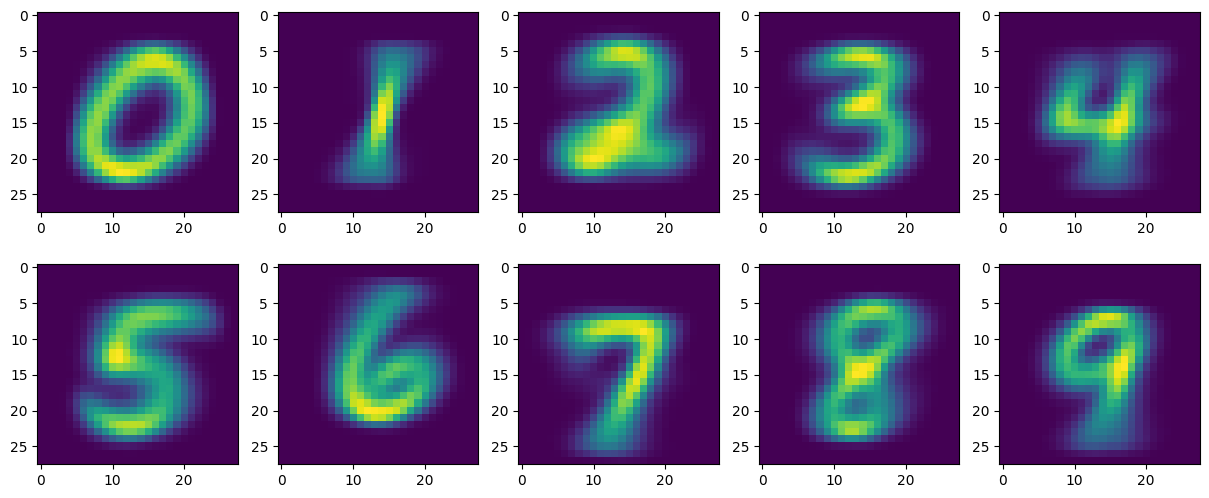

In [45]:
# Creamos subplots

fig, axes = plt.subplots (nrows = 2, ncols = 5, figsize = (15,6))

axes = axes.flatten ()

for i in range(n_classes):
  # Extraemos los parámetros de la clase i
  theta_img = (thetas_estimates * 255)[:,i].reshape (img_shape)

  # Visualizamos la imagen
  axes [i].imshow (theta_img)

plt.show()


## Generación de Nuevos Dígitos

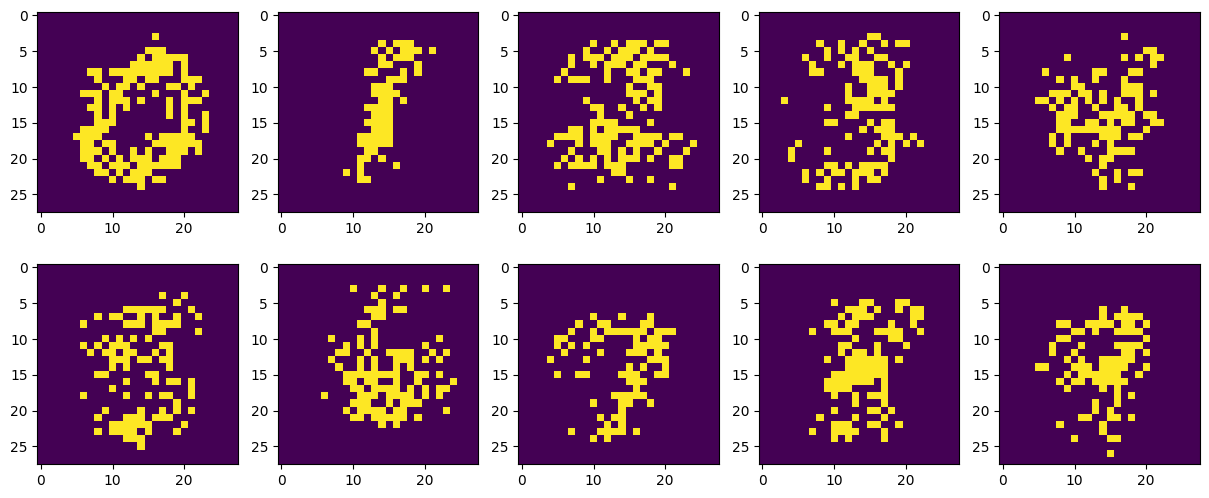

In [46]:
n_classes = 10
img_shape = (28,28)

# Creamos subploots

fig, axes = plt.subplots (nrows = 2, ncols = 5, figsize = (15,6))

axes = axes.flatten ()

for i in range(n_classes):

  theta_class = thetas_estimates [:,i]

  # Generamos muestras de acuerdos a dichos parámetros (parámetros de distribución de Bernouilli)

  sampled_image = np.random.binomial (n=1, p=theta_class)

  sampled_image = sampled_image.reshape (img_shape)

  # Visualizamos la imagen
  axes[i].imshow (sampled_image)

plt.show()
